In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation
from quinex_application.visualisation.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata_new.parquet")

# **Load Data**

In [3]:
df_paper = visualisation.load_df("../data/paper/paper_dataset.parquet")
df_paper = df_paper[df_paper["Quinex"] == True]

📂 Loaded DataFrame from '../data/paper/paper_dataset.parquet' with 81073 rows


In [4]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata_new.parquet")
quinex_df = visualisation.load_df("../data/visualisation_files/df_technologies_nan_new.parquet")

📂 Loaded DataFrame from '../data/quinex/df_quinex_metadata_new.parquet' with 31636 rows
📂 Loaded DataFrame from '../data/visualisation_files/df_technologies_nan_new.parquet' with 3244657 rows


In [5]:
metadata_df = metadata_df.drop_duplicates(subset="DOI", keep="first")
len(metadata_df)

31636

In [ ]:
len(metadata_df[metadata_df["countries"].apply(lambda x: len(x) >= 1)])

In [ ]:
# metadata_df = metadata.add_sjr_to_metadata(
#     metadata_df,
#     sjr_folder="../data/paper/impactfactor",
#     source_col="source",
#     year_col="publication_year",
#     #source_rename_dict=source_rename_dict
# )

# metadata_df = metadata_df.merge(
#     df_paper[['DOI', 'Source title']],
#     on='DOI',
#     how='left'
# )

# mask = metadata_df['SJR'].isna()
# metadata_fallback = metadata_df.loc[mask].copy()
# metadata_fallback = metadata.add_sjr_to_metadata(
#     metadata_fallback,
#     sjr_folder="../data/paper/impactfactor",
#     source_col="Source title",
#     year_col="publication_year",
# )
# metadata_df.loc[mask, 'SJR'] = metadata_fallback['SJR'].values
# metadata_df.to_parquet("../data/quinex/df_quinex_metadata_new.parquet")

# **Analysis Metadata**

c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:987: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


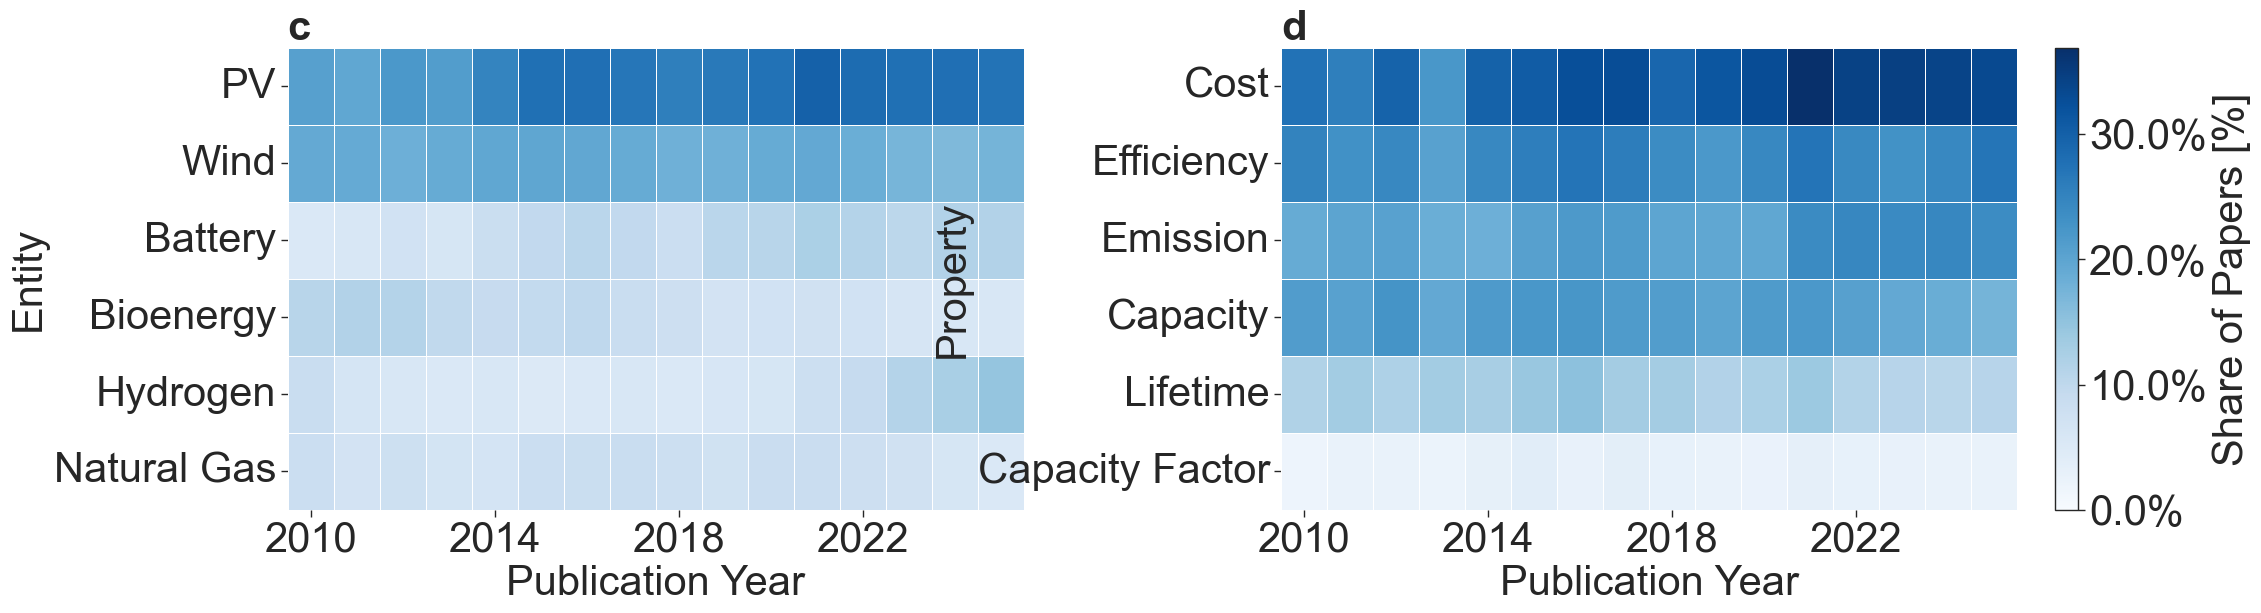

In [5]:
fig, piv_entity, piv_property = metadata.mention_trend_heatmap(quinex_df[quinex_df["publication_year"] < 2026], "entity_base_mapping", "property_base_mapping", figsize=(24,6), font_size=30, top_n=6, cmap="Blues")
fig.savefig("../data/figures/metadata/ent_prop_distribution.pdf", bbox_inches='tight')

In [ ]:
metadata._load_population_data("../data/visualisation_files/world_population.xlsx")

Missing country info: 1542 papers (5.80%)
Missing SJR info: 1069 papers (4.02%)


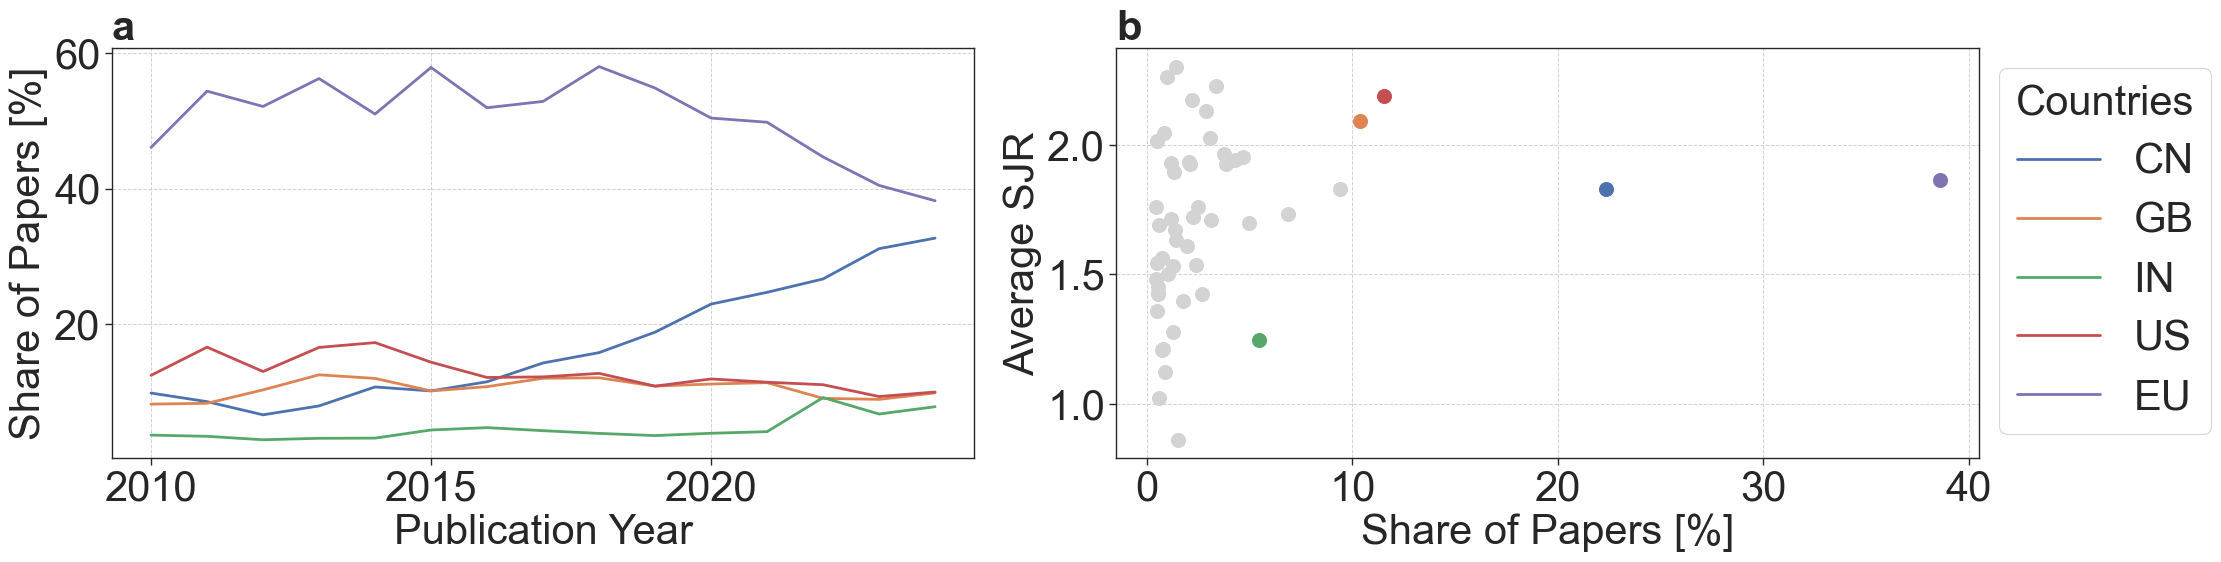

In [10]:
eu_countries = {
    "EU": ["DE", "FR", "IT", "ES", "NL", "BE", "AT", "SE", "DK", "PL", "GR", "PT", "CZ", "FI", "RO", "HU", "BG", "HR", "SI", "SK", "IE"]
}

fig, pivot_countries, avg_sjr = metadata.countries_share_and_sjr(
    metadata_df,
    top_n_line = 5, 
    top_n_scatter = 50, 
    figsize = (24, 6), 
    font_size=30, 
    legend_bbox=(0.885,0.55),
    max_year=2024,
    #normalize_by_population=True,
    population_excel_path="../data/visualisation_files/world_population.xlsx",
    # normalize_by_gdp=True,
    # gdp_excel_path="../data/visualisation_files/world_gdp.xls",
    country_groups=eu_countries
)
fig.savefig("../data/figures/metadata/share_top_countries.pdf", bbox_inches='tight')

In [ ]:
from matplotlib.patches import Ellipse

ax = fig.axes[1]  # Scatter-Plot Achse (rechts)

# Ellipse separat hinzufügen
ellipse = Ellipse(
    xy=(0.69, 0.7), 
    width=0.58,          # Breite in x-Richtung
    height=0.5,         # Höhe in y-Richtung  
    transform=ax.transAxes,
    facecolor='none',    # Nur Rand
    edgecolor='black', 
    linewidth=2
)
ax.add_patch(ellipse)

# Text separat
ax.text(0.69, 0.7, "Nordics", transform=ax.transAxes, 
        ha='center', va='center', fontsize=30)

fig
# PDF speichern
fig.savefig("../data/figures/metadata/share_top_countries_per_capita.pdf", bbox_inches='tight')

In [ ]:
fig

# **Strategic Country Comparison (8 Countries)**
Interesting pairings placed side-by-side:
- **Row 1**: China vs USA (Top 2 global research leaders)
- **Row 2**: Germany vs Japan (Traditional industrial powers)
- **Row 3**: South Korea vs India (Rising Asian research hubs)
- **Row 4**: UK vs Iran (Contrasting research ecosystems)

In [6]:
# Create DataFrames for additional top research nations
def get_df_by_country(metadata_df, quinex_df, country_code):
    """Filter quinex_df for publications from a specific country."""
    pubs = metadata_df[metadata_df['countries'].apply(lambda x: country_code in x)]
    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]

df_ch = get_df_by_country(metadata_df, quinex_df, "CN")  # China
df_us = get_df_by_country(metadata_df, quinex_df, "US")  # United States
df_jp = get_df_by_country(metadata_df, quinex_df, "JP")  # South Korea
df_de = get_df_by_country(metadata_df, quinex_df, "DE")  # Germany
df_kr = get_df_by_country(metadata_df, quinex_df, "KR")  # South Korea
df_in = get_df_by_country(metadata_df, quinex_df, "IN")  # India
df_gb = get_df_by_country(metadata_df, quinex_df, "GB")  # United Kingdom
df_ir = get_df_by_country(metadata_df, quinex_df, "IR")  # Iran

print(f"China: {len(df_ch)} entries")
print(f"USA: {len(df_us)} entries")
print(f"Japan: {len(df_jp)} entries")
print(f"Germany: {len(df_de)} entries")
print(f"South Korea: {len(df_kr)} entries")
print(f"India: {len(df_in)} entries")
print(f"UK: {len(df_gb)} entries")
print(f"Iran: {len(df_ir)} entries")

China: 520051 entries
USA: 302736 entries
Japan: 66056 entries
Germany: 243743 entries
South Korea: 53310 entries
India: 132561 entries
UK: 266587 entries
Iran: 120265 entries


In [ ]:
# Strategic 8-country comparison with interesting pairings side-by-side
# Row 1: China vs USA (Top 2 global research leaders)
# Row 2: Germany vs Japan (Traditional industrial powers)  
# Row 3: South Korea vs India (Rising Asian research hubs)
# Row 4: UK vs Iran (Contrasting research ecosystems)

fig, piv_entity = metadata.mention_trend_heatmap_multi_entities(
    dfs = [df_ch, df_us, df_de, df_jp, df_kr, df_in, df_gb, df_ir],
    titles = [
        "a) China", "b) USA", 
        "c) Germany", "d) Japan", 
        "e) South Korea", "f) India", 
        "g) United Kingdom", "h) Iran"
    ],
    entity_col = "entity_base_mapping",
    figsize=(24, 6),
    font_size=30, 
    top_n=7, 
    cmap="Blues"
)
#fig.savefig("../data/figures/metadata/ent_8countries.pdf", bbox_inches='tight')

### EU, China, USA Comparison (3 columns)

In [ ]:
len(df_eu["DOI"].value_counts())

In [9]:
print(f"EU: {len(df_eu['DOI'].value_counts())} entries")
print(f"China: {len(df_ch['DOI'].value_counts())} entries")
print(f"USA: {len(df_us['DOI'].value_counts())} entries")
print(f"UK: {len(df_gb['DOI'].value_counts())} entries")
print(f"Japan: {len(df_jp['DOI'].value_counts())} entries")
print(f"India: {len(df_in['DOI'].value_counts())} entries")

EU: 9789 entries
China: 5698 entries
USA: 2946 entries
UK: 2624 entries
Japan: 635 entries
India: 1446 entries


EU: 989808 entries
China: 520051 entries
USA: 302736 entries


c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:792: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.12, 1, 1])


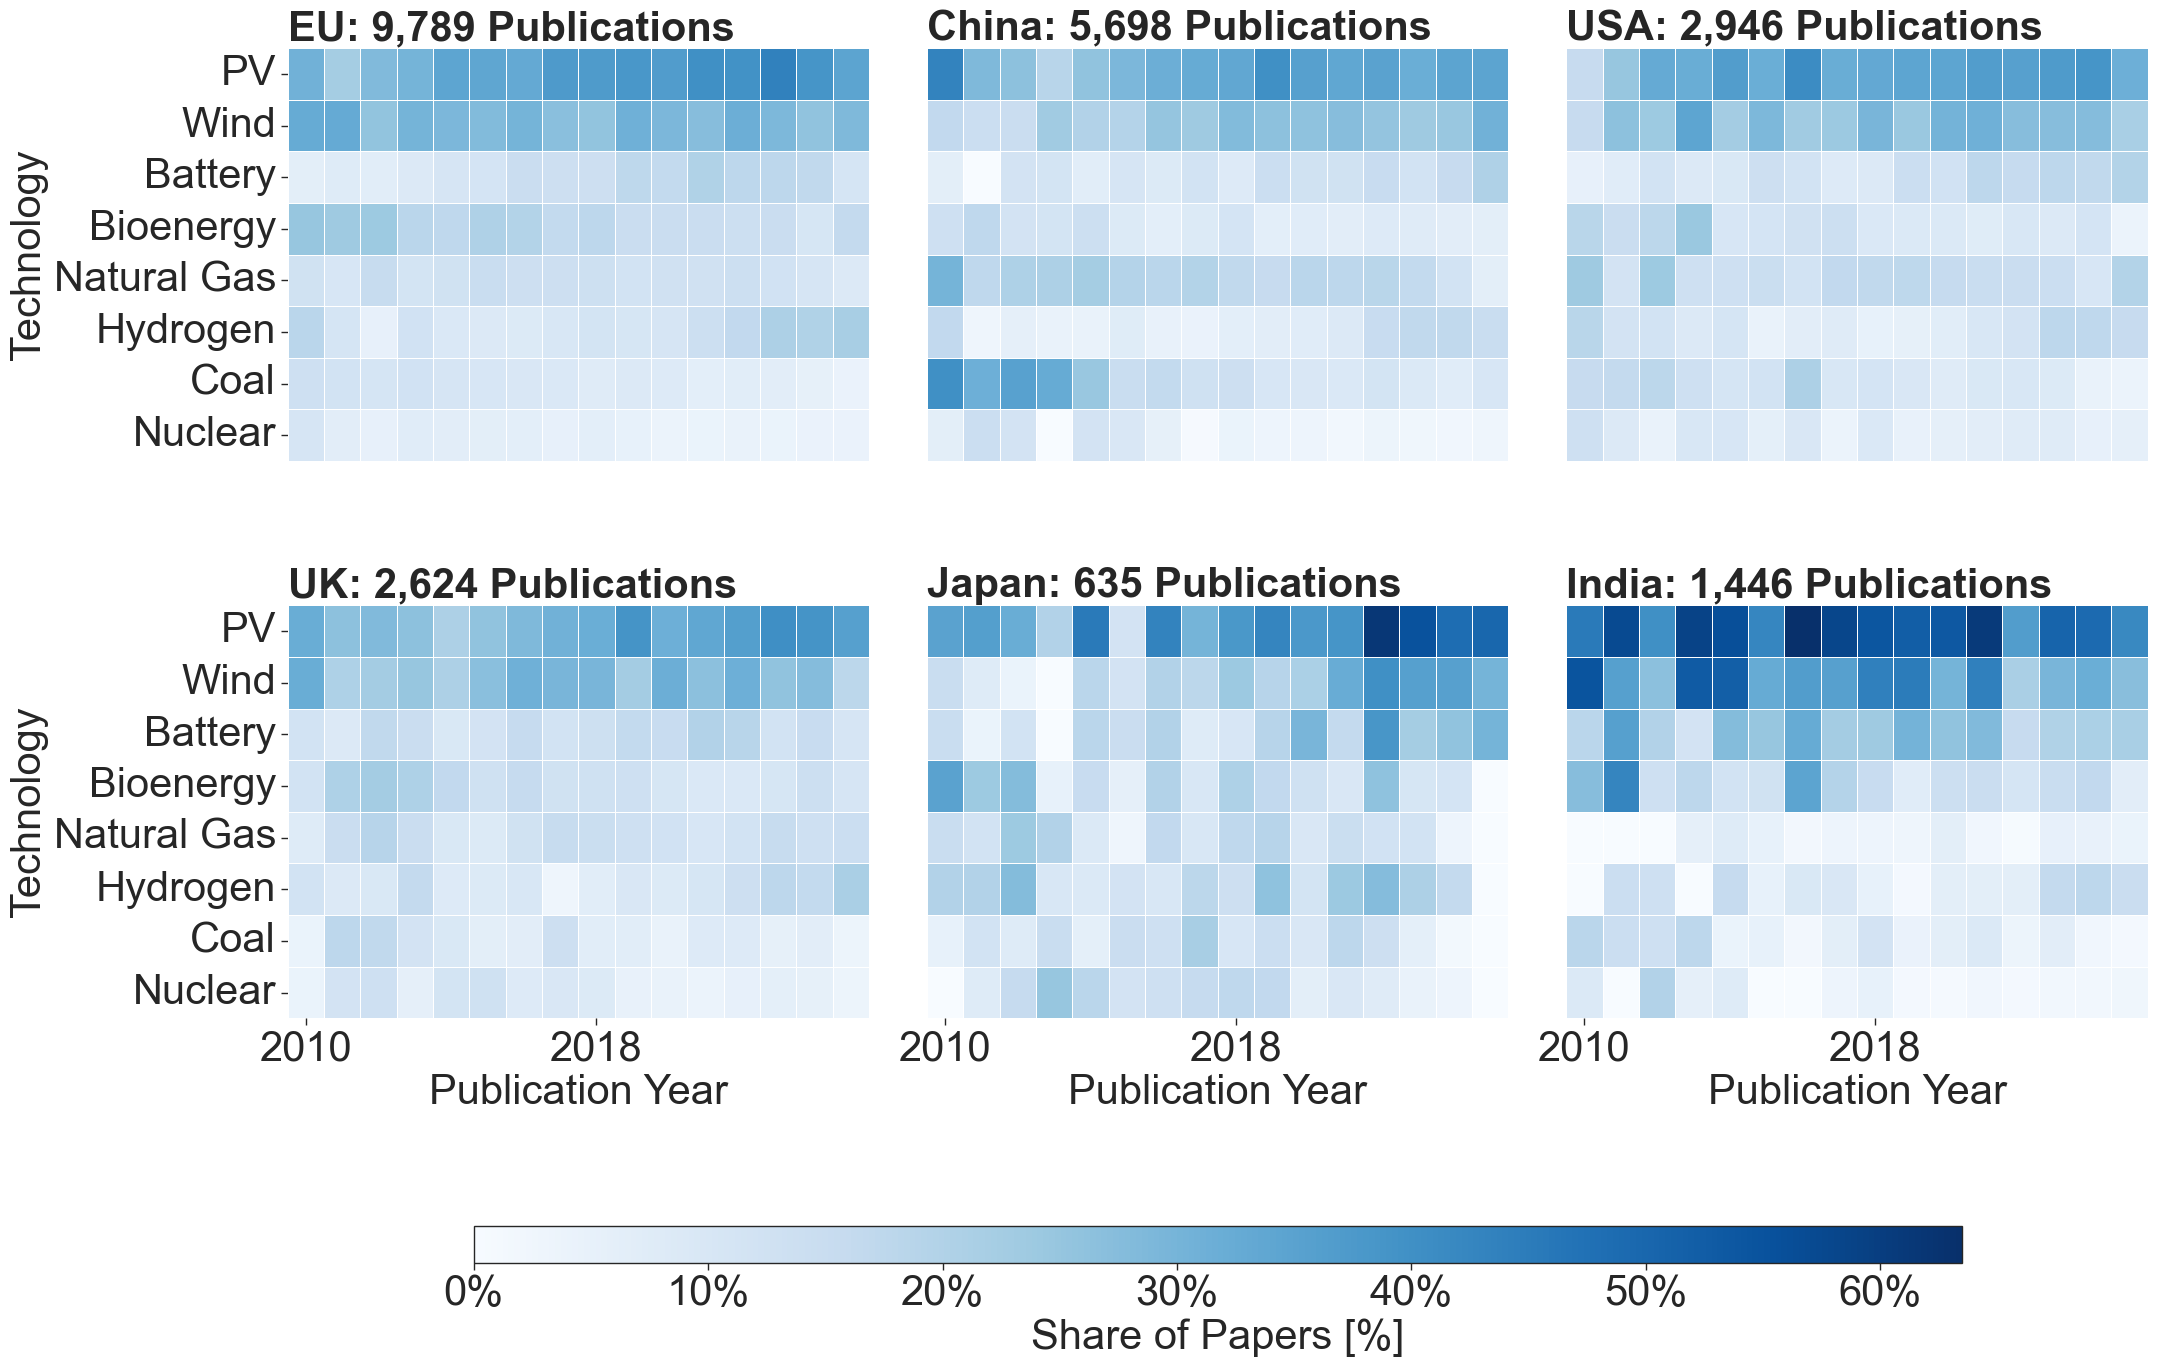

In [10]:
# Create EU DataFrame by aggregating EU countries
def get_df_by_countries(metadata_df, quinex_df, country_codes):
    """Filter quinex_df for publications from a list of countries."""
    pubs = metadata_df[metadata_df['countries'].apply(
        lambda x: any(code in x for code in country_codes)
    )]
    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]

eu_codes = ["DE", "FR", "IT", "ES", "NL", "BE", "AT", "SE", "DK", "PL", "GR", "PT", "CZ", "FI", "RO", "HU", "BG", "HR", "SI", "SK", "IE"]
df_eu = get_df_by_countries(metadata_df, quinex_df, eu_codes)

print(f"EU: {len(df_eu)} entries")
print(f"China: {len(df_ch)} entries")
print(f"USA: {len(df_us)} entries")

# 3 countries/regions: 3 columns, 1 row
fig, piv_entity = metadata.mention_trend_heatmap_multi_entities(
    dfs = [df_eu, df_ch, df_us, df_gb, df_jp, df_in],
    titles = [
        "EU: 9,789 Publications",
        "China: 5,698 Publications", 
        "USA: 2,946 Publications", 
        "UK: 2,624 Publications", 
        "Japan: 635 Publications", 
        "India: 1,446 Publications"
    ],
    entity_col = "entity_base_mapping",
    figsize=(24, 9),
    font_size=30, 
    top_n=8, 
    cmap="Blues",
    n_cols=3
)
fig.savefig("../data/figures/metadata/ent_6countries.pdf", bbox_inches='tight')

In [ ]:
piv_entity[4]

In [ ]:
fig

In [ ]:


# 2. Nur Zeilen mit gültigem SJR und CN filtern (optional, falls du nur China willst)
filtered_df = metadata_df[
    (metadata_df['countries'].apply(lambda x: "CN" in x)) 
    #& (metadata_df['SJR'].notna())
]
filtered_df["topics"].value_counts()
# 3. Durchschnitt von SJR pro Jahr berechnen
# avg_sjr_per_year = filtered_df.groupby('publication_year')['SJR'].mean()

# print(avg_sjr_per_year)

In [ ]:
avg_sjr[avg_sjr["countries"] =="CN"]

In [ ]:
avg_sjr[avg_sjr["share_of_paper"] > 0.02].sort_values(by='share_of_paper', ascending=False)

In [ ]:
# Filter anwenden
df = avg_sjr[avg_sjr["countries"].isin(countries_by_continent["Asia"])]
df["average_sjr"].mean()

In [ ]:
countries_by_continent = {
    "Africa": [
        "MZ","NE","NG","LY","MA","ML","MR","MW","NA","RW","ZA","ZM","TG","TD","BW","CD",
        "CF","CM","CI","DJ","DZ","EG","ET","GH","GM","GN","KE","LS","LR","SN","BJ",
        "MU","MZ","RE","SC","SD","SL","SO","SS","SZ","TZ","TN","UG","ZW",'BI',"BF"
    ],
    "Asia": [
        "AF","AM","AZ","BD","BT","BN","KH","CN","IN","ID","IR","IQ","IL","JP","JO",
        "KZ","KW","KG","LA","LB","MY","MV","MN","MM","NP","OM","PK","PS","PH","QA","SA","SG",
        "KR","LK","SY","TW","TJ","TH","TR","AE","UZ","VN","YE","HK","MO","BH","CV"
    ],
    "Europe": [
        "AL","AD","AT","BY","BE","BA","BG","HR","CY","CZ","DK","EE","FO","FI","FR","DE",
        "GR","HU","IS","IE","IT","LV","LT","LU","MK","MT","ME",
        "NL","NO","PL","PT","RO","RU","RS","SK","SI","ES","SE","CH","UA","GB","XK"
    ],
    "North America": [
        "BB","CA","CR","CU","DO","GL","JM","MX","NI","PA","PR","TT","US","GP"
    ],
    "South America": [
        "AR","BO","BR","CL","CO","EC","GF","PE","PY","SR","VE","AW"
    ],
    "Oceania": [
        "AU","FJ","NZ","PG","WS",
    ]
}